# Ride-Hailing Customer Feedback Intelligence & Automated Response

## Ola vs Uber Play Store Reviews

### Objective

This project analyzes customer reviews from Ola and Uber to identify critical customer feedback, understand common complaint patterns, and use Generative AI to generate personalized and empathetic customer support responses for the most critical cases.

### Project Steps

1. Import libraries
2. Load and combine the data
3. Understand the raw data
4. Data cleaning (missing values, text cleaning, empty reviews)
5. Identify critical reviews (rule-based)
6. Ola vs Uber critical review rate
7. Review length
8. Complaint keyword analysis (common words, keyword percentages, categories)
9. Select 3 critical, detailed reviews
10. Generate apology emails with Generative AI (Gemini)
11. Conclusion

## Step 1: Import Libraries
We use beginner-friendly Python and Pandas methods throughout the project.

In [1]:
import pandas as pd                      # tables and data cleaning
import os                                # work with file paths
from collections import Counter          # count how often words appear
import warnings
warnings.filterwarnings("ignore")        # hide non-important warnings
import matplotlib.pyplot as plt

## Step 2: Load and Combine the Data
Download the dataset, read the Ola and Uber files, and join them into one table with a new `app` column.

In [2]:
!pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("khushipitroda/ola-vs-uber-play-store-reviews")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Lenovo\.cache\kagglehub\datasets\khushipitroda\ola-vs-uber-play-store-reviews\versions\1


In [4]:
# Show the files inside the downloaded dataset folder
print(os.listdir(path))

['Ola Customer Reviews.csv', 'Uber Customer Reviews.csv']


In [5]:

# 1. Read the two files
ola = pd.read_csv(os.path.join(path, "Ola Customer Reviews.csv"))
uber = pd.read_csv(os.path.join(path, "Uber Customer Reviews.csv"))

# 2. Add a new column so we know which app each review belongs to
ola["app"] = "Ola"
uber["app"] = "Uber"

# 3. Join both tables into one
df = pd.concat([ola, uber], ignore_index=True)

# 4. Look at the data
print(df.shape)  


(1427314, 14)


In [6]:
print("Ola shape:", ola.shape)
print("Uber shape:", uber.shape)

Ola shape: (357698, 14)
Uber shape: (1069616, 14)


In [7]:
# Check the column names in both datasets
print("Ola columns:")
print(ola.columns.tolist())

print("Uber columns:")
print(uber.columns.tolist())

Ola columns:
['source', 'review_id', 'user_name', 'review_title', 'review_description', 'rating', 'thumbs_up', 'review_date', 'developer_response', 'developer_response_date', 'appVersion', 'laguage_code', 'country_code', 'app']
Uber columns:
['source', 'review_id', 'user_name', 'review_title', 'review_description', 'rating', 'thumbs_up', 'review_date', 'developer_response', 'developer_response_date', 'appVersion', 'laguage_code', 'country_code', 'app']


In [8]:
# View a few rows from each dataset
print(ola.head())
print(uber.head())

        source                             review_id         user_name  \
0  Google Play  fbc7ffc9-5a89-446e-87fd-d69bf4a7f984     Puipuii Ralte   
1  Google Play  5a0051fb-220a-45b2-ba94-a15a2949218f      Deepak Kumar   
2  Google Play  71ebf933-b734-474d-bb65-a18c90906ed2  Ahamed Azarudeen   
3  Google Play  e1cc0010-60b3-4126-99c2-e8549088566a        Rahil Syed   
4  Google Play  77cf1be1-b428-4493-ae25-e0f288f79b8f           vin 007   

  review_title                                 review_description  rating  \
0          NaN  The map in Ola is so messed up, i have to pay ...       1   
1          NaN                            Deepak Kumar.... 🙏🙏🙏🙏🙏]       5   
2          NaN  Such aa irresponsible app more then I waiting ...       1   
3          NaN                                              Worst       1   
4          NaN  Too much expensive .. try UBer... They are pro...       1   

   thumbs_up          review_date developer_response developer_response_date  \
0        0.0

## Step 3: Understand the Raw Data
Before cleaning, we check missing values, duplicates, ratings, and data sources.

In [9]:
# Basic information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1427314 entries, 0 to 1427313
Data columns (total 14 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   source                   1427314 non-null  str    
 1   review_id                1427314 non-null  str    
 2   user_name                1427313 non-null  str    
 3   review_title             3071 non-null     str    
 4   review_description       1427125 non-null  str    
 5   rating                   1427314 non-null  int64  
 6   thumbs_up                1424243 non-null  float64
 7   review_date              1427314 non-null  str    
 8   developer_response       323033 non-null   str    
 9   developer_response_date  321868 non-null   str    
 10  appVersion               1103394 non-null  str    
 11  laguage_code             1427314 non-null  str    
 12  country_code             1427314 non-null  str    
 13  app                      1427314 non-null  str    
dt

In [10]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check rating values
print("Rating distribution:")
print(df["rating"].value_counts().sort_index())

# Check review sources
print("Source distribution:")
print(df["source"].value_counts())

Duplicate rows: 0
Rating distribution:
rating
1    457095
2     57293
3     65919
4    107917
5    739090
Name: count, dtype: int64
Source distribution:
source
Google Play    1424243
App Store         3071
Name: count, dtype: int64


In [11]:
# Calculate the percentage of missing values in each column
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df) * 100).round(2)

print(missing_percentage.sort_values(ascending=False))

review_title               99.78
developer_response_date    77.45
developer_response         77.37
appVersion                 22.69
thumbs_up                   0.22
review_description          0.01
rating                      0.00
user_name                   0.00
source                      0.00
review_id                   0.00
review_date                 0.00
laguage_code                0.00
country_code                0.00
app                         0.00
dtype: float64


### Inference: Raw Data
- The combined dataset has 1,427,314 reviews (Ola + Uber) and 14 columns. There are no duplicate rows.
- Ratings are not balanced. About 51.8% are 5-star and 32.0% are 1-star, so people mostly give extreme ratings.
- 99.78% of reviews come from Google Play, so the results mostly reflect Play Store users.
- `review_title` is 99.78% empty, because only App Store reviews have titles. I did not use it.
- Only 189 reviews had no text, which is very small.

## Step 4: Data Cleaning
The assessment asks us to handle missing values and clean the text. We keep the original dataset unchanged and work on a copy called `clean_df`.

### Step 4.1: Handle Missing Values
Drop rows with no review text, fill missing `thumbs_up` with 0, and check for reviews that contain only spaces.

In [12]:
# Create a copy so the raw merged data stays unchanged
clean_df = df.copy()

clean_df = clean_df.dropna(subset=["review_description"])

# These columns are not useful for our analysis
clean_df = clean_df.drop(["review_title", "user_name"], axis=1)

# thumbs_up is empty when nobody liked the review, so 0 is a fair value
clean_df["thumbs_up"] = clean_df["thumbs_up"].fillna(0)

# Reviews with only spaces are hidden missing data, dropna cannot see them
blank_count = (clean_df["review_description"].str.strip() == "").sum()
print("Blank-only reviews:", blank_count)

# Keep only reviews that really have text
clean_df = clean_df[clean_df["review_description"].str.strip() != ""].copy()
print("Shape after missing value handling:", clean_df.shape)

Blank-only reviews: 0
Shape after missing value handling: (1427125, 12)


### Inference: Missing Values
- I dropped 189 rows with no review text, because there is nothing to analyse without text. 1,427,125 rows remain.
- I checked for reviews with only spaces. There were 0.
- Missing `thumbs_up` was filled with 0, because it means nobody liked the review. I did not drop those rows.
- I dropped `review_title` and `user_name` in my working copy. The original data is unchanged.

### Step 4.2: Clean the Text
We keep the original review in `review_description` and create a separate `clean_text` column.

In [13]:
# Step 1: make all text lowercase, so "Worst" and "worst" are the same word
clean_df["clean_text"] = clean_df["review_description"].str.lower()
# Step 2: remove apostrophes, so "don't" becomes "dont" (one word)
clean_df["clean_text"] = clean_df["clean_text"].str.replace("'", "", regex=False)
# Step 3: replace everything except letters and spaces with a space
clean_df["clean_text"] = clean_df["clean_text"].str.replace(r"[^a-z\s]", " ", regex=True)
# Step 4: remove extra spaces
clean_df["clean_text"] = clean_df["clean_text"].str.split().str.join(" ")

### Step 4.3: Remove Empty Reviews and Count Words
Some reviews become empty after cleaning (for example, only emojis). We remove them and add a `word_count` column.

In [14]:
# Remove reviews that became empty after cleaning (for example, only emojis)
clean_df = clean_df[clean_df["clean_text"] != ""].copy()

# Count the words in each review
clean_df["word_count"] = clean_df["clean_text"].str.split().str.len()
print("Rows after removing empty reviews:", len(clean_df))

Rows after removing empty reviews: 1406692


### Inference: Text Cleaning
- Steps: lowercase, remove apostrophes ("don't" becomes "dont"), replace everything except letters with a space, remove extra spaces.
- 20,433 reviews became empty (only emojis, numbers or non-English letters) and were removed. 1,406,692 reviews remain.
- Side effect: numbers and prices are removed, and non-English words are lost.
- The original text stays in `review_description`.

### Step 4.4: Fix Column Name, Dates and Developer Response
Correct the spelling of the language column, convert `review_date` to a date type, and add a flag showing whether the developer replied.

In [15]:
# Correct the spelling of the language column
clean_df = clean_df.rename(columns={"laguage_code": "language_code"})

# Convert review_date from text to datetime
clean_df["review_date"] = pd.to_datetime(clean_df["review_date"])

# Create a simple flag showing whether a developer response exists
clean_df["developer_responded"] = clean_df["developer_response"].notna()

print("Date type:", clean_df["review_date"].dtype)
print("Start date:", clean_df["review_date"].min())
print("End date:", clean_df["review_date"].max())
print("Developer response:")
print(clean_df["developer_responded"].value_counts())

Date type: datetime64[us]
Start date: 2012-09-21 08:23:46
End date: 2023-08-10 17:48:51
Developer response:
developer_responded
False    1085443
True      321249
Name: count, dtype: int64


## Step 5: Identify Critical Reviews (Rule-Based, No Machine Learning)
According to the assessment, reviews with a rating of 1 or 2 are treated as **Critical**. We use this simple rule instead of Machine Learning.

In [16]:
# Select reviews with 1 or 2 star ratings
critical_df = clean_df[clean_df["rating"] <= 2].copy()

print("Total critical reviews:", len(critical_df))
print("Critical reviews by rating:")
print(critical_df["rating"].value_counts().sort_index())

Total critical reviews: 509160
Critical reviews by rating:
rating
1    452375
2     56785
Name: count, dtype: int64


## Step 6: Ola vs Uber Critical Review Rate
Because Uber has many more reviews than Ola, raw critical-review counts are not a fair comparison. We compare the percentage of reviews that are critical within each app.

In [17]:
# Count all reviews for each app
app_total = clean_df["app"].value_counts()

# Count critical reviews for each app
app_critical = critical_df["app"].value_counts()

# Calculate the critical-review percentage
critical_percentage = (app_critical / app_total * 100).round(2)

app_comparison = pd.DataFrame({
    "Total Reviews": app_total,
    "Critical Reviews": app_critical,
    "Critical Percentage": critical_percentage
})

print(app_comparison)

      Total Reviews  Critical Reviews  Critical Percentage
app                                                       
Uber        1052292            321289                30.53
Ola          354400            187871                53.01


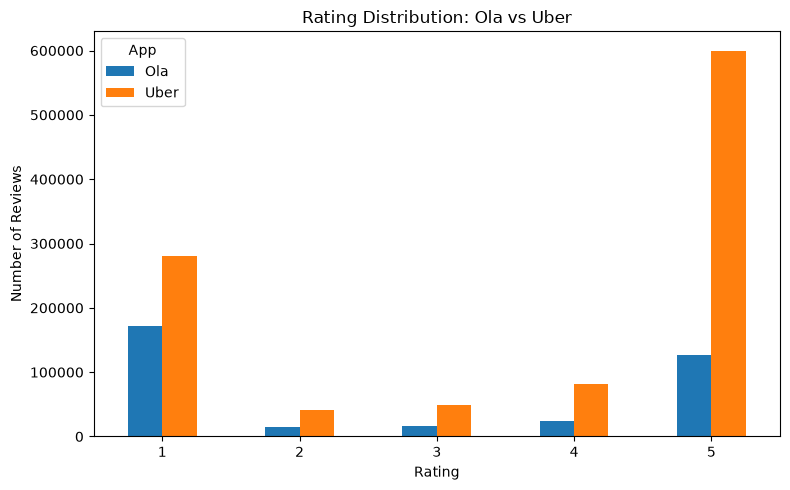

In [18]:
# Rating distribution by app
rating_by_app = pd.crosstab(clean_df["rating"], clean_df["app"])

rating_by_app.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Rating Distribution: Ola vs Uber")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.legend(title="App")
plt.tight_layout()
plt.show()

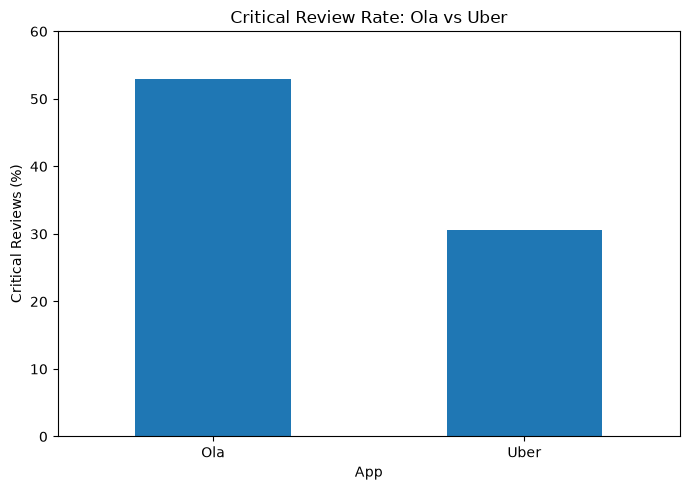

In [19]:
# Critical review rate comparison
critical_rate_chart = app_comparison.loc[["Ola", "Uber"], "Critical Percentage"]

critical_rate_chart.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Critical Review Rate: Ola vs Uber")
plt.xlabel("App")
plt.ylabel("Critical Reviews (%)")
plt.xticks(rotation=0)
plt.ylim(0, 60)
plt.tight_layout()
plt.show()

### Inference: Critical Reviews
- There are 509,160 critical reviews (1 or 2 stars), about 36.2% of all reviews. Most of them (452,375) are 1-star.
- Uber has more critical reviews in count (321,289 vs 187,871), but it also has about 3 times more reviews in total.
- By percentage, Ola is much worse: 53.01% of Ola reviews are critical, against 30.53% for Uber.
- Limitation: some 1 or 2 star reviews can be positive in meaning, so stars alone are not perfect.

## Step 7: Review Length
How long are critical reviews? This also helps us choose detailed reviews later.

In [20]:
# Summary of review length (in words) for critical reviews
print(critical_df["word_count"].describe())

count    509160.000000
mean         28.131603
std          27.913292
min           1.000000
25%           7.000000
50%          19.000000
75%          40.000000
max         706.000000
Name: word_count, dtype: float64


### Inference: Review Length
- The median critical review has 19 words, and 75% have 40 words or fewer. Most people write short complaints.
- The average (28 words) is higher because a few very long reviews (up to 706 words) pull it up.

## Step 8: Complaint Keyword Analysis
We look at the critical reviews to find the most common complaint areas. First we count common words, then we measure fixed complaint words as a percentage, and finally we group them into themes.

### Step 8.1: Most Common Words (using `Counter`)
Common words that add little meaning are removed first, then `Counter` counts the rest.

In [21]:
# Common words that do not show a complaint (removed before counting)
stopwords = {"the", "and", "is", "to", "of", "it", "in", "for", "this", "that", "you", "my", "me", "i", "a", "an", "was", "are", "with", "on", "they", "have", "but", "so", "be", "at", "not", "app", "uber", "ola", "very", "just", "your", "from", "when", "has", "its", "cant", "dont", "can", "will", "all", "or", "as", "do", "get", "got", "even", "after", "their", "were", "then", "there", "had", "now", "use"}

# Count the most common useful words in a list of reviews
def top_words(texts, n=20):
    counter = Counter()
    for text in texts:
        for word in text.split():
            if word not in stopwords and len(word) > 2:
                counter[word] += 1
    return counter.most_common(n)

# Top words for each app (critical reviews only)
print("Ola:", top_words(critical_df[critical_df["app"] == "Ola"]["clean_text"]))
print("Uber:", top_words(critical_df[critical_df["app"] == "Uber"]["clean_text"]))

Ola: [('ride', 59511), ('driver', 54538), ('worst', 47068), ('service', 42427), ('drivers', 42007), ('customer', 31398), ('time', 30745), ('cab', 26481), ('bad', 24327), ('money', 23927), ('cancel', 23891), ('experience', 19962), ('booking', 17838), ('pay', 17522), ('support', 17115), ('book', 17109), ('payment', 15902), ('any', 15019), ('extra', 14325), ('auto', 14070)]
Uber: [('driver', 86870), ('ride', 76888), ('drivers', 64055), ('service', 52456), ('time', 51523), ('worst', 42467), ('cancel', 37867), ('trip', 36407), ('customer', 36190), ('bad', 31734), ('pay', 24700), ('money', 24233), ('cab', 23847), ('charged', 21962), ('never', 21778), ('one', 21488), ('experience', 21450), ('account', 21002), ('payment', 20698), ('more', 20460)]


### Inference: Most Common Words
- Words like "ride", "driver", "drivers", "cab" and "service" appear in almost every taxi review, so they are topic words, not complaints.
- Real complaint signals: "worst", "bad", "money", "cancel", "pay", "payment" and "support" (Ola), and "worst", "bad", "cancel", "charged" and "money" (Uber).
- Raw counts cannot be compared across apps, because Uber has about 3 times more reviews. So I use percentages next.

### Step 8.2: Complaint Keyword Percentages
Raw counts are not fair across apps, so we measure the percentage of critical reviews that contain each complaint word.

In [22]:
# Complaint words to look for (fixed list chosen by me)
complaint_words = ["cancel", "refund", "charge", "money", "payment", "support", "delay", "wait", "rude", "scam", "fraud", "fare", "price", "unprofessional", "fake", "stuck"]

rows = {}
for word in complaint_words:
    has_word = critical_df["clean_text"].str.contains(r"\b" + word, regex=True)  # word starting with it (cancel, cancelled)
    rows[word] = has_word.groupby(critical_df["app"]).mean() * 100               # % of critical reviews per app

keyword_table = pd.DataFrame(rows).T.round(1)
print(keyword_table.sort_values("Ola", ascending=False))

app              Ola  Uber
cancel          21.3  19.1
charge          13.9  12.5
money           10.0   6.3
support          7.7   4.8
payment          6.6   5.3
fare             5.6   3.8
wait             4.3   6.6
price            3.6   4.2
rude             2.3   1.5
fraud            2.2   1.2
refund           2.1   2.0
unprofessional   1.1   1.2
scam             1.0   0.9
fake             0.6   0.4
delay            0.4   0.4
stuck            0.4   0.5


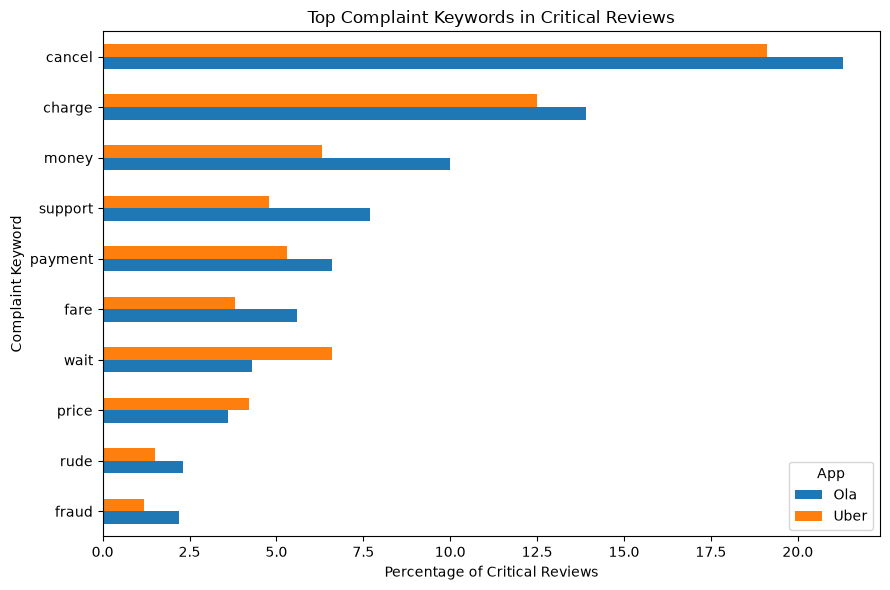

In [23]:
# Top complaint keywords
top_keywords = keyword_table.sort_values("Ola", ascending=False).head(10)

top_keywords[["Ola", "Uber"]].sort_values("Ola").plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top Complaint Keywords in Critical Reviews")
plt.xlabel("Percentage of Critical Reviews")
plt.ylabel("Complaint Keyword")
plt.legend(title="App")
plt.tight_layout()
plt.show()

### Inference: Complaint Keywords
- "cancel" is the top complaint for both apps (Ola 21.3%, Uber 19.1%). About 1 in 5 critical reviews mentions it.
- Ola is higher for money (10.0% vs 6.3%), support (7.7% vs 4.8%), payment (6.6% vs 5.3%) and fare (5.6% vs 3.8%).
- Uber is higher for waiting (6.6% vs 4.3%).
- Words like scam, fake, delay and stuck are under 1.1%, so they are minor complaints.
- Limitation: this is my own word list, and one review can contain many words, so the percentages do not add up to 100.

### Step 8.3: Complaint Categories
We group the complaint words into four themes: Cancellation, Payment and Charges, Customer Support, and Driver Behaviour.

In [24]:
# Group complaint words into themes
categories = {
    "Cancellation": "cancel",
    "Payment and Charges": "money|payment|pay|charge|refund|fare|price",
    "Customer Support": "support|complaint|helpline",
    "Driver Behaviour": "rude|unprofessional|abuse|misbehav",
}

# % of critical reviews in each theme, for Ola and Uber
cat_rows = {}
for name, words in categories.items():
    has_cat = critical_df["clean_text"].str.contains(r"\b(?:" + words + ")", regex=True)
    cat_rows[name] = has_cat.groupby(critical_df["app"]).mean() * 100

category_table = pd.DataFrame(cat_rows).T.round(1)
print(category_table)

app                   Ola  Uber
Cancellation         21.3  19.1
Payment and Charges  35.1  30.8
Customer Support      9.9   6.4
Driver Behaviour      3.8   2.9


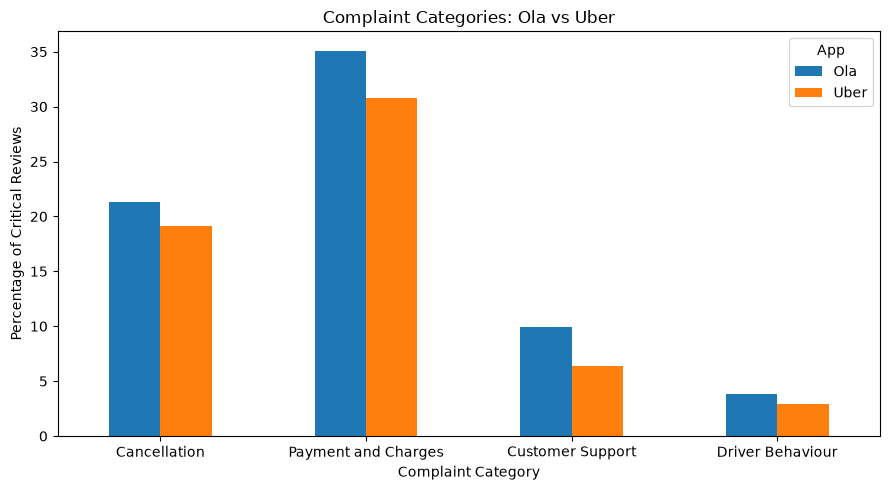

In [25]:
# Complaint category comparison
category_table[["Ola", "Uber"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Complaint Categories: Ola vs Uber")
plt.xlabel("Complaint Category")
plt.ylabel("Percentage of Critical Reviews")
plt.xticks(rotation=0)
plt.legend(title="App")
plt.tight_layout()
plt.show()

### Inference: Complaint Categories
- Payment and Charges is the biggest category for both apps (Ola 35.1%, Uber 30.8%).
- Ola is higher in all four categories, especially Customer Support (9.9% vs 6.4%).
- Driver Behaviour is small for both (Ola 3.8%, Uber 2.9%).
- These are keyword groups, so they show likely complaint areas, not confirmed ones.

## Step 9: Select 3 Critical, Detailed Reviews
We filter 1-star reviews with 60 to 150 words that contain a complaint word, read a random sample, and pick 3 for the AI emails.

In [26]:
# Complaint words used to find useful reviews
pattern = "cancel|refund|charge|money|payment|support|fare|rude"

# Rule: 1-star, 60 to 150 words, and contains a complaint word
mask = (critical_df["rating"] == 1) & (critical_df["word_count"].between(60, 150)) & critical_df["clean_text"].str.contains(pattern)
candidates = critical_df[mask]
print("Candidates:", len(candidates))

# Read a random 10 to choose from
for i, row in candidates.sample(10, random_state=7).iterrows():
    print(i, row["app"], "|", row["review_description"], "\n")

Candidates: 45804
142060 Ola | It's the worst app I've ever used to book a ride the estimated fare is not even close to actual fare and they even charged for the toll amount that actually paid by me for some trips,when I contacted them about this issue after a day they said will solve the problems only on the same day the trip was taken.if anybody wants book a ride don't use this app it will make regret later moreover their call support is the worst scam ever if u complaint about any they'll solve it without taking any action 

412993 Uber | I have issue to report but I don't see any option to report it. Whenever I book sedan most of the time there CNG gas cylinder and that's consume most of bootspace . I need to cancel my today's because I had two moderate bag and 4 small bags with 4 passengers. I couldn't find any option in uber to report this (smaller bootspace because CNG cylinder) , please help 

1013146 Uber | Falta controle de qualidade dos motoristas. Motorista parou próximo ao

In [27]:
selected_ids = [142060, 768147, 80478]   # the 3 reviews you picked
selected = critical_df.loc[selected_ids, ["app", "rating", "review_description"]]
print(selected)

         app  rating                                 review_description
142060   Ola       1  It's the worst app I've ever used to book a ri...
768147  Uber       1  Worst company. Drivers accept the ride and the...
80478    Ola       1  What the hell is wrong with Ola, being such a ...


### Inference: Selecting 3 Reviews
- I filtered 1-star reviews with 60 to 150 words and a complaint word. 45,804 reviews passed.
- I read a random sample of 10 and picked 3 manually (2 Ola, 1 Uber).
- Reviews of this length have enough detail for a personal email, and they are longer than most critical reviews.
- The 3 cases cover the main complaints found earlier: payment and charges, cancellation and poor support.

## Step 10: Generate Apology Emails with Generative AI (Gemini)
We send each of the 3 selected reviews to Gemini and ask it to write a short, empathetic apology email as a customer support agent.

### Step 10.1: Set Up Gemini
Install the library and enter the API key with `getpass`, so the key is never saved in the notebook.

In [28]:
# install Google's Gemini library
!pip install -q -U google-genai

In [34]:
import os
import time
from getpass import getpass
from google import genai

os.environ["GEMINI_API_KEY"] = getpass("Paste your Gemini API key: ")  # key stays out of the notebook
client = genai.Client()

MODELS = [
    "gemini-3.5-flash-lite",
    "gemini-3.1-flash-lite",
    "gemini-2.5-flash-lite",
    "gemini-2.5-flash",
    "gemini-3.8-flash",
]# models to try, in order

def ask_gemini(prompt):
    for model in MODELS:
        for attempt in range(3):
            try:
                response = client.models.generate_content(model=model, contents=prompt)
                return response.text
            except Exception as e:
                print(model, "failed:", str(e)[:80])
                time.sleep(10)
    return None

print(ask_gemini("Say hello in one short sentence."))  # quick test


Paste your Gemini API key:  ········


Hello there, how can I help you today?


In [33]:
for m in client.models.list():
    if "flash" in m.name:
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


### Step 10.2: Write the Prompt and Generate the 3 Emails
The prompt tells the model to be polite, mention the exact problem, avoid promises, avoid new facts, and stay under 120 words.

In [36]:
# Build the instruction (prompt) that is sent to Gemini
def make_prompt(app, review):
    prompt = f"""
You are a customer support agent at {app}.
Write a short apology email for the customer review below.
Style: polite, warm and empathetic.
Mention the exact problem the customer faced.
Do not promise refunds, compensation or fixed timelines.
Do not add facts that are not in the review.
Keep it under 120 words and sign off as "{app} Support Team".

Customer review:
{review}
"""
    return prompt

# Generate one email for each of the 3 selected reviews
email_results = []
for case_no, (idx, row) in enumerate(selected.iterrows(), start=1):
    email = ask_gemini(make_prompt(row["app"], row["review_description"]))
    email_results.append({"case": case_no, "app": row["app"], "review": row["review_description"], "email": email})
    print(f"----- Case {case_no} ({row['app']}) -----")
    print(email, "\n")
    time.sleep(3)

# Save a copy, so you do not lose the emails if the notebook closes
pd.DataFrame(email_results).to_csv("generated_emails.csv", index=False)

----- Case 1 (Ola) -----
Dear Customer,

Thank you for sharing your experience with us. I am truly sorry for the frustration you faced regarding the mismatch between your estimated and actual fares, as well as being charged for the toll amount you already paid. 

It is also disappointing to hear that our support team did not assist you properly when you raised these issues after a day, and that your experience with our call support fell far short of your expectations. We completely understand how upsetting this is, and we genuinely appreciate you bringing it to our attention so we can review these concerns.

Warm regards,

Ola Support Team 

----- Case 2 (Uber) -----
Hi,

Thank you for reaching out to us. I am truly sorry to hear about your recent experience. It is deeply concerning to hear that your drivers accepted your rides, asked for your destination, demanded extra money, and then cancelled, especially while you were left facing cancellation charges. I understand how frustrating 

### Step 10.3: The 3 AI-Generated Emails
Below are the three selected reviews and the emails Gemini wrote for them.

#### Case 1: Ola (1-star review)

**Customer review:**

> It's the worst app I've ever used to book a ride the estimated fare is not even close to actual fare and they even charged for the toll amount that actually paid by me for some trips,when I contacted them about this issue after a day they said will solve the problems only on the same day the trip was taken.if anybody wants book a ride don't use this app it will make regret later moreover their call support is the worst scam ever if u complaint about any they'll solve it without taking any action

**AI-generated email:**

> Dear Customer,
>
> We are truly sorry for the frustrating experience you had with us. We understand how disappointing it was to face discrepancies between estimated and actual fares, and to be charged for tolls you had already paid. We also apologize for the poor support you received when reaching out, particularly regarding our same-day reporting limitation and complaints being closed without any proper action.
>
> Your feedback is incredibly valuable to us. We are sharing your concerns directly with our internal teams to improve both our app performance and our customer support quality. Thank you for bringing this to our attention.
>
> Warm regards,
>
> Ola Support Team

#### Case 2: Uber (1-star review)

**Customer review:**

> Worst company. Drivers accept the ride and then call us and ask where to go and then ask for extra money and then cancel it. Uber company do not take any action against this. There is no way we can talk to any customer care support. If we cancel the trip we have to pay cancellation charges. But rider do not have to pay anything even if they cancel. I suggest you all not download this app and do not book any ride in uber.

**AI-generated email:**

> Dear Customer,
>
> We are truly sorry for the incredibly frustrating experience you had. We understand how upsetting it is when drivers accept your ride, call to ask your destination, demand extra money, and then cancel. We also hear your concerns regarding the difficulty in reaching our customer support, feeling that no action is taken, and being charged cancellation fees while drivers do not have to pay anything when they cancel.
>
> Please know we take your feedback seriously. We are continuously working to improve our platform, address driver behavior, and make our support more accessible. Thank you for sharing your experience with us.
>
> Warmly,
>
> Uber Support Team

#### Case 3: Ola (1-star review)

**Customer review:**

> What the hell is wrong with Ola, being such a big company you send notification to clear dues for a ride whose payment was already done and customer cannot even reach customer care to make a complain n start the services again. Contact your driver and ask if payment was done in cash because of unavailability of online payment, why it was not completed. Why harassing a customer to pay for a ride that has already been paid. Do we look fool or your driver was fool to leave a customer without paying

**AI-generated email:**

> Subject: Sincere apologies from Ola
>
> Dear Customer,
>
> We are truly sorry for the frustrating experience you had. We completely understand your anger regarding notifications to clear dues for a ride you already paid in cash because online payment was unavailable. It is also deeply regrettable that you could not reach our customer care to lodge a complaint and restart your services.
>
> Please accept our sincere apologies for the distress and harassment this has caused you. We are looking into this matter and will contact your driver to verify why the cash payment was not marked as completed.
>
> Thank you for your patience.
>
> Warmly,
>
> Ola Support Team

### Inference: AI Emails
- The emails mention the exact problems from each review and keep an empathetic tone.
- Problem found: some emails add promises that are not in the review (for example "sharing your concerns with internal teams" and "will contact your driver"). My prompt said not to add facts, but the model still did.
- So a human should check every AI email before sending. I could improve the prompt by adding "Do not promise any action".

## Step 11: Conclusion

**Key findings**
- Ola has a much higher share of critical reviews (53.01%) than Uber (30.53%).
- "Cancel" is the top complaint word for both apps (Ola 21.3%, Uber 19.1%).
- Payment and Charges is the biggest complaint theme (Ola 35.1%, Uber 30.8%). Ola is higher in all four themes, especially Customer Support.
- Uber is higher only for waiting time (6.6% vs 4.3%).
- Gemini wrote clear and empathetic emails for the 3 selected reviews, but two of them added promises that were not in the review, so a human should check each email before it is sent.

**Limitations**
- The analysis is rule-based (keywords and star ratings), so it can miss complaints outside my word list.
- Some 1 or 2 star reviews are positive in meaning.
- Cleaning keeps only English letters, so numbers and non-English words are lost.
- 99.78% of reviews come from Google Play.